# Perspective Transformation

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

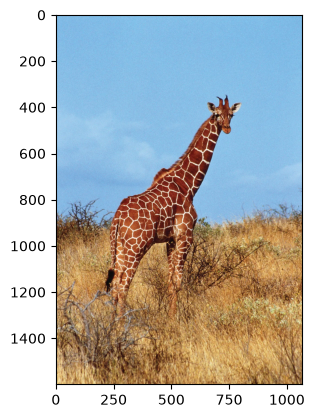

In [2]:
img = cv2.imread('./data/giraffe-Kenya.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)

In [3]:
img_rgb.shape

(1600, 1067, 3)

## Perspective transformation

In [25]:
def check_4_points(img, old_pts, new_pts):

    image = img.copy()

    for op, np in zip(old_pts, new_pts):
        cv2.circle(img=image, center=op, radius=15, color=(255,0,0), thickness=-1)
        cv2.circle(img=image, center=np, radius=15, color=(0,255,0), thickness=-1)

    return image

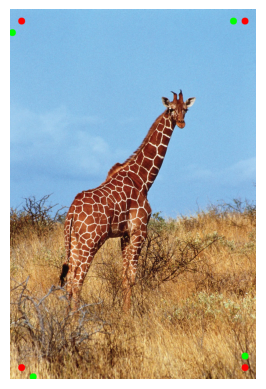

In [26]:
old_points = [(50,50), (1017,50), (50,1550), (1017,1550)]  # RED color
new_points = [(10,100), (967,50), (100,1590), (1017,1500)] # Green color

result = check_4_points(img_rgb, old_points, new_points)

plt.imshow(result)
plt.axis('off')
# plt.legend()
plt.show()

In [21]:
height, width, _ = img_rgb.shape

# input_points: where four points are located in the original image.
input_points = np.float32([[50, 50], [width-50,50], [50,height-50], [width-50,height-50]])

# output_points: where those same four points should end up in the transformed image.
output_points = np.float32([[10,100], [width-100,50], [100,height-10], [width-50,height-100]])

| Points | Input coordinate | Output coordinate |
|--------|------------------|-------------------|
|   P1   |      (50, 50)    |      (10, 100)    |
|   P2   |    (1017, 50)    |      (967, 50)    |
|   P3   |    (50, 1550)    |    (100, 1590)    |
|   P4   |  (1017, 1550)    |   (1017, 1500)    |


- P1 moves left and down.
- P2 moves left and stays higher.
- P3 moves right and down.
- P4 moves right and up.

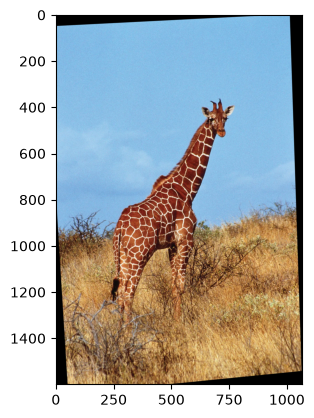

In [ ]:
'''
Trasformation matrix for Perspective trasformation

3x3

a, b, c
d, e, f
g, h, 1

a,b,c is responsioble for horizontal scaling, rotation and tranlation
d,e,f is responsioble for vertical scaling, rotation and tranlation
g,h  : Perspective components that account for depth and skew

'''

# The transformation matrix calculated from the corresponding points.
M = cv2.getPerspectiveTransform(src=input_points, dst=output_points)

# Apply that matrix to produce the transformed image.
perspective_img = cv2.warpPerspective(src=img_rgb, M=M, dsize=(width, height))

# Show image
plt.imshow(perspective_img)

## Affine transformation

In [27]:
def check_4_points(img, old_pts, new_pts):

    image = img.copy()

    for op, np in zip(old_pts, new_pts):
        cv2.circle(img=image, center=op, radius=15, color=(255,0,0), thickness=-1)
        cv2.circle(img=image, center=np, radius=15, color=(0,255,0), thickness=-1)

    return image

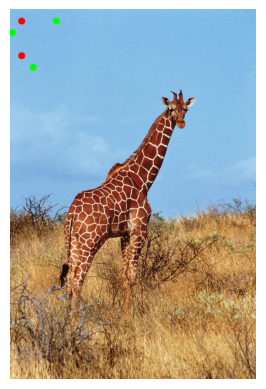

In [ ]:
height, width, _ = img_rgb.shape

# old_points: where four points are located in the original image.
old_points = [[50,50], [200, 50], [50, 200]]

# new_points: where those same four points should end up in the transformed image.
new_points = [[10,100], [200, 50], [100, 250]]

result = check_4_points(img_rgb, old_points, new_points)

plt.imshow(result)
plt.axis('off')
plt.show()

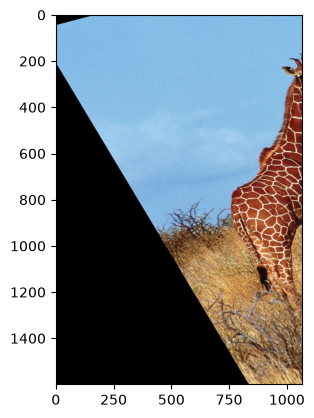

In [ ]:
# input_points: where four points are located in the original image.
input_points = np.float32([[50,50], [200, 50], [50, 200]])

# output_points: where those same four points should end up in the transformed image.
output_points = np.float32([[10,100], [200, 50], [100, 250]])

'''
Trasformation matrix for Perspective trasformation

3x3

a, b, c
d, e, f
g, h, 1

a,b,c is responsioble for horizontal scaling, rotation and tranlation
d,e,f is responsioble for vertical scaling, rotation and tranlation
g,h  : Perspective components that account for depth and skew

'''

# The transformation matrix calculated from the corresponding points.
M = cv2.getAffineTransform(src=input_points, dst=output_points)

# Apply that matrix to produce the transformed image.
affine_img = cv2.warpAffine(src=img_rgb, M=M, dsize=(width, height))

# Show image
plt.imshow(affine_img)

## Rotation

(np.float64(-0.5), np.float64(1066.5), np.float64(1599.5), np.float64(-0.5))

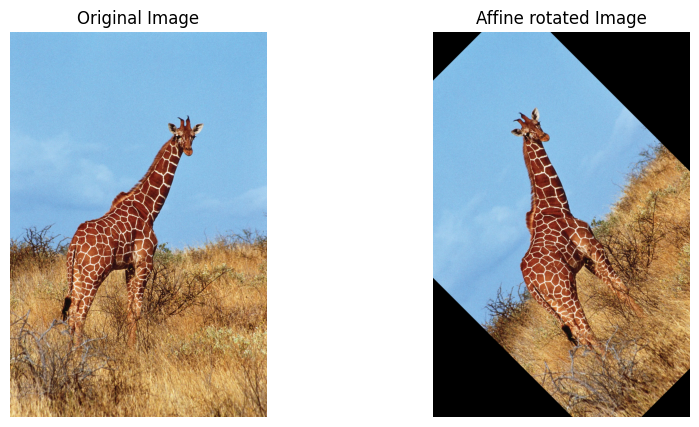

In [15]:
angle = 45
center = (cols // 2, rows // 2)
scale = 1.0

M = cv2.getRotationMatrix2D(center,angle, scale)

rotated_image = cv2.warpAffine(image_rgb, M, (cols, rows))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(rotated_image)
plt.title("Affine rotated Image")
plt.axis("off")

(np.float64(-0.5), np.float64(2133.5), np.float64(1599.5), np.float64(-0.5))

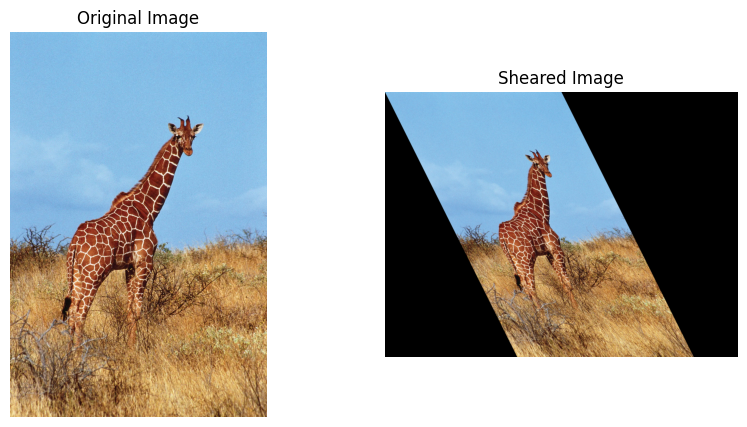

In [19]:
# angle = 45
# center = (cols // 2, rows // 2)
# scale = 1.0

shear_x, shear_y = 0.5, 0

M = np.float32([[1, shear_x, 0], 
           [shear_y, 1, 0]])


sheared_image = cv2.warpAffine(image_rgb, M, (cols*2, rows))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(sheared_image)
plt.title("Sheared Image")
plt.axis("off")

# Translation

(np.float64(-0.5), np.float64(1066.5), np.float64(1599.5), np.float64(-0.5))

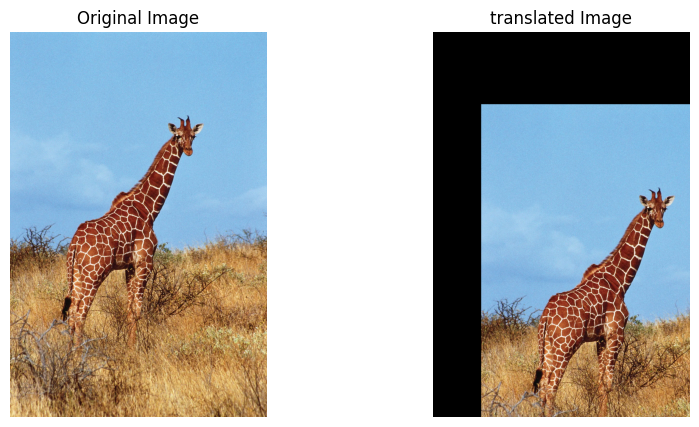

In [20]:
# angle = 45
# center = (cols // 2, rows // 2)
# scale = 1.0

tx, ty = 200, 300

M = np.float32([[1, 0, tx], 
           [0, 1, ty]])


translated_image = cv2.warpAffine(image_rgb, M, (cols, rows))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(translated_image)
plt.title("translated Image")
plt.axis("off")